
# Northbridge University Admissions Analysis
## Task 2 — Construct a Programming Solution

This notebook loads and combines recruiter_A.csv and recruiter_B.xlsx, validates and prepares the data, performs exploratory data analysis (EDA), trains and compares two classification models, and evaluates ethical risks.

The model is intended to support admissions officers, not to make fully automated admissions decisions. Historical admission outcomes reflect previous decisions and do not necessarily measure future academic success.


#Pseudocode: Northbridge University Admissions Analysis
```
START
  Load recruiter_A.csv and recruiter_B.xlsx.
  Validate column names, data types and applicant IDs.
  Add recruiter labels and combine the datasets.
  Inspect missing values, duplicates and invalid values.
  Clean and prepare the data.
  Perform descriptive analysis and visualisation.
  Separate predictors from the target variable.
  Split the data into training and testing sets.
  Train Logistic Regression and Random Forest models.
  Evaluate both models using classification metrics.
  Examine group-level fairness indicators.
  Compare results and make recommendations.
END
```

In [18]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

# Upload both assessment datasets in Google Colab.
from google.colab import files
uploaded = files.upload()

print("Files uploaded:", list(uploaded.keys()))


Saving recruiter_A.csv to recruiter_A (2).csv
Saving recruiter_B.xlsx to recruiter_B (2).xlsx
Files uploaded: ['recruiter_A (2).csv', 'recruiter_B (2).xlsx']


In [19]:
# Read the CSV and Excel datasets.
recruiter_a = pd.read_csv("recruiter_A.csv")
recruiter_b = pd.read_excel("recruiter_B.xlsx")

# Display dataset dimensions.
print("Recruiter A shape:", recruiter_a.shape)
print("Recruiter B shape:", recruiter_b.shape)

# Display the first five records from each dataset.
display(recruiter_a.head())
display(recruiter_b.head())

# Check column names.
print("Recruiter A columns:")
print(recruiter_a.columns.tolist())

print("\nRecruiter B columns:")
print(recruiter_b.columns.tolist())


Recruiter A shape: (4000, 12)
Recruiter B shape: (4000, 12)


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,A00001,59.1,59.3,2.94,State,Humanities,47.3,0,Female,Other,NaN,1
1,A00002,80.0,78.0,3.60,State,Humanities,49.9,1,Male,Mixed,NaN,1
2,A00003,72.8,60.4,3.31,State,Arts,145.9,0,Male,Asian,NaN,1
3,A00004,54.9,60.7,3.52,State,STEM,63.1,0,Female,White,NaN,1
4,A00005,64.2,56.8,2.99,State,Arts,175.9,1,Male,Black,NaN,1


,student_id,prior_attainment_score,admissions_test_score,personal_statement_score,school_type,intended_subject_area,distance_from_campus_km,first_generation_student,gender,ethnicity,disability_status,admission_outcome
0,B00001,61.3,76.1,3.80,State,Arts,95.6,0,Female,Other,NaN,0
1,B00002,56.6,60.9,2.81,State,Humanities,80.9,0,Female,Other,NaN,1
2,B00003,72.4,73.5,3.56,Independent,STEM,70.5,1,Male,White,NaN,1
3,B00004,76.3,75.4,2.46,State,Social Sciences,118.4,0,Male,Other,NaN,1
4,B00005,65.1,57.8,3.75,State,Humanities,88.3,1,Female,White,Learning,1


Recruiter A columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']

Recruiter B columns:
['student_id', 'prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'first_generation_student', 'gender', 'ethnicity', 'disability_status', 'admission_outcome']


In [20]:
expected_columns = [
    "student_id",
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score",
    "school_type",
    "intended_subject_area",
    "distance_from_campus_km",
    "first_generation_student",
    "gender",
    "ethnicity",
    "disability_status",
    "admission_outcome"
]

# Check for missing or unexpected columns.
for name, df in [
    ("Recruiter A", recruiter_a),
    ("Recruiter B", recruiter_b)
]:
    print(f"\n{name}")
    print("Missing columns:",
          sorted(set(expected_columns) - set(df.columns)))
    print("Unexpected columns:",
          sorted(set(df.columns) - set(expected_columns)))

# Stop if the schemas do not match the required structure.
if (set(recruiter_a.columns) != set(expected_columns)
        or set(recruiter_b.columns) != set(expected_columns)):
    raise ValueError(
        "Check the column names against the assessment brief before merging."
    )

# Standardise column order and identify each data source.
recruiter_a = recruiter_a[expected_columns].copy()
recruiter_b = recruiter_b[expected_columns].copy()

recruiter_a["recruiter_source"] = "A"
recruiter_b["recruiter_source"] = "B"

# Combine the records row-wise.
data_raw = pd.concat(
    [recruiter_a, recruiter_b],
    ignore_index=True
)

print("\nCombined dataset shape:", data_raw.shape)
print("Unique student IDs:", data_raw["student_id"].nunique())
print("Duplicate student IDs:",
      data_raw["student_id"].duplicated().sum())

display(
    data_raw.groupby("recruiter_source")
    .size()
    .rename("number_of_applications")
    .to_frame()
)


Recruiter A
Missing columns: []
Unexpected columns: []

Recruiter B
Missing columns: []
Unexpected columns: []

Combined dataset shape: (8000, 13)
Unique student IDs: 8000
Duplicate student IDs: 0


,number_of_applications
recruiter_source,
A,4000
B,4000


In [21]:

print("Dataset dimensions:", data_raw.shape)

# Inspect column data types.
display(data_raw.dtypes.rename("data_type").to_frame())

# Calculate missing values and their percentages.
missing_audit = pd.DataFrame({
    "missing_count": data_raw.isna().sum(),
    "missing_percentage": (
        data_raw.isna().mean() * 100
    ).round(2)
})

display(
    missing_audit.sort_values(
        "missing_count",
        ascending=False
    )
)

# Check duplicate records.
print("Duplicate complete rows:", data_raw.duplicated().sum())
print(
    "Duplicate student IDs:",
    data_raw["student_id"].duplicated().sum()
)

# Summary statistics for numeric columns.
display(data_raw.select_dtypes(include=np.number).describe().T)

# Inspect the values recorded in categorical columns.
categorical_columns = [
    "school_type",
    "intended_subject_area",
    "gender",
    "ethnicity",
    "disability_status",
    "first_generation_student",
    "admission_outcome"
]

for column in categorical_columns:
    print(f"\nValues in {column}:")
    print(data_raw[column].value_counts(dropna=False))


Dataset dimensions: (8000, 13)


,data_type
student_id,object
prior_attainment_score,float64
admissions_test_score,float64
personal_statement_score,float64
school_type,object
intended_subject_area,object
distance_from_campus_km,float64
first_generation_student,int64
gender,object
ethnicity,object


,missing_count,missing_percentage
disability_status,6210,77.62
intended_subject_area,1,0.01
distance_from_campus_km,1,0.01
school_type,1,0.01
student_id,0,0.00
personal_statement_score,0,0.00
admissions_test_score,0,0.00
prior_attainment_score,0,0.00
first_generation_student,0,0.00
gender,0,0.00


Duplicate complete rows: 0
Duplicate student IDs: 0


,count,mean,std,min,25%,50%,75%,max
prior_attainment_score,8000.0,70.011375,9.899891,32.00,63.40,70.00,76.70,105.70
admissions_test_score,8000.0,65.162725,11.983186,12.50,57.00,65.40,73.40,104.70
personal_statement_score,8000.0,3.209556,0.806279,-0.34,2.65,3.21,3.76,6.45
distance_from_campus_km,7999.0,89.533142,52.817444,2.40,51.00,79.50,117.20,519.10
first_generation_student,8000.0,0.349000,0.476684,0.00,0.00,0.00,1.00,1.00
admission_outcome,8000.0,0.606250,0.488611,0.00,0.00,1.00,1.00,1.00



Values in school_type:
school_type
State            5205
Independent      1957
International     834
S                   2
I                   1
NaN                 1
Name: count, dtype: int64

Values in intended_subject_area:
intended_subject_area
Social Sciences    2019
STEM               1997
Arts               1992
Humanities         1989
Soc                   1
A                     1
NaN                   1
Name: count, dtype: int64

Values in gender:
gender
Female    4026
Male      3806
Other      164
M            2
F            2
Name: count, dtype: int64

Values in ethnicity:
ethnicity
Other    1633
Mixed    1614
Asian    1597
Black    1593
White    1563
Name: count, dtype: int64

Values in disability_status:
disability_status
NaN         6210
Learning     807
Mental       492
Physical     491
Name: count, dtype: int64

Values in first_generation_student:
first_generation_student
0    5208
1    2792
Name: count, dtype: int64

Values in admission_outcome:
admission_outcome
1  

In [22]:

# Create a copy to preserve the original combined dataset.
data = data_raw.copy()

# Remove exact duplicate rows.
data = data.drop_duplicates().copy()

# Remove unnecessary spaces from text fields.
text_columns = data.select_dtypes(include="object").columns

for column in text_columns:
    data[column] = data[column].map(
        lambda value: value.strip()
        if isinstance(value, str) else value
    )

# Standardise only clearly identifiable gender abbreviations.
data["gender"] = data["gender"].replace({
    "M": "Male",
    "F": "Female",
    "m": "Male",
    "f": "Female"
})

# Convert numeric columns to numeric format.
numeric_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "personal_statement_score",
    "distance_from_campus_km",
    "first_generation_student",
    "admission_outcome"
]

for column in numeric_columns:
    data[column] = pd.to_numeric(
        data[column],
        errors="coerce"
    )

# Define valid ranges according to the assessment brief.
valid_ranges = {
    "prior_attainment_score": (0, 100),
    "admissions_test_score": (0, 100),
    "personal_statement_score": (1, 5),
    "distance_from_campus_km": (0, np.inf),
    "first_generation_student": (0, 1),
    "admission_outcome": (0, 1)
}

# Report invalid values before treating them as missing.
range_audit = []

for column, (lower, upper) in valid_ranges.items():
    invalid = (
        data[column].notna()
        & (
            (data[column] < lower)
            | (data[column] > upper)
        )
    )

    range_audit.append({
        "column": column,
        "invalid_count": int(invalid.sum()),
        "minimum_observed": data[column].min(),
        "maximum_observed": data[column].max()
    })

    # Flag invalid values as missing rather than guessing corrections.
    data.loc[invalid, column] = np.nan

display(pd.DataFrame(range_audit))

# Retain only records with a valid, known binary target.
data = data[
    data["admission_outcome"].isin([0, 1])
].copy()

data["admission_outcome"] = (
    data["admission_outcome"].astype(int)
)

# Report duplicate IDs before removing repeated records.
duplicate_ids = data[
    data["student_id"].duplicated(keep=False)
]["student_id"].unique()

print("Duplicate IDs requiring investigation:", len(duplicate_ids))

# Provisional handling: keep the first record per ID.
# Confirm duplicates with the data owner before real deployment.
if len(duplicate_ids) > 0:
    data = data.drop_duplicates(
        subset=["student_id"],
        keep="first"
    ).copy()

print("Cleaned dataset shape:", data.shape)

display(
    data["admission_outcome"]
    .value_counts()
    .rename("number_of_applicants")
    .to_frame()
)


,column,invalid_count,minimum_observed,maximum_observed
0,prior_attainment_score,4,32.00,105.70
1,admissions_test_score,10,12.50,104.70
2,personal_statement_score,133,-0.34,6.45
3,distance_from_campus_km,0,2.40,519.10
4,first_generation_student,0,0.00,1.00
5,admission_outcome,0,0.00,1.00


Duplicate IDs requiring investigation: 0
Cleaned dataset shape: (8000, 13)


,number_of_applicants
admission_outcome,
1,4850
0,3150


In [23]:

# Count applications and successful offers.
number_of_records = len(data)

number_of_offers = (
    data["admission_outcome"] == 1
).sum()

overall_offer_rate = (
    data["admission_outcome"].mean() * 100
)

print("Total applications:", number_of_records)
print("Number of offers:", number_of_offers)
print(f"Overall offer rate: {overall_offer_rate:.2f}%")


Total applications: 8000
Number of offers: 4850
Overall offer rate: 60.62%


In [24]:

# Count offers and non-offers by gender.
gender_counts = pd.crosstab(
    data["gender"],
    data["admission_outcome"],
    margins=True
)

gender_counts = gender_counts.rename(
    columns={0: "No offer", 1: "Offer"}
)

display(gender_counts)

# Calculate historical offer rates by gender.
gender_offer_rates = (
    data.groupby("gender")["admission_outcome"]
    .agg(["count", "mean"])
)

gender_offer_rates = gender_offer_rates.rename(
    columns={
        "count": "applications",
        "mean": "offer_rate"
    }
)

gender_offer_rates["offer_rate"] *= 100

display(gender_offer_rates.round(2))


admission_outcome,No offer,Offer,All
gender,,,
Female,1575,2453,4028
Male,1501,2307,3808
Other,74,90,164
All,3150,4850,8000


,applications,offer_rate
gender,,
Female,4028,60.90
Male,3808,60.58
Other,164,54.88


In [25]:

# Count applications received from each recruitment partner.
applications_by_recruiter = (
    data["recruiter_source"]
    .value_counts()
    .sort_index()
)

display(
    applications_by_recruiter.rename(
        "number_of_applications"
    ).to_frame()
)

# Calculate offer rates by recruiter.
recruiter_offer_rates = (
    data.groupby("recruiter_source")["admission_outcome"]
    .agg(["count", "mean"])
)

recruiter_offer_rates = recruiter_offer_rates.rename(
    columns={
        "count": "applications",
        "mean": "offer_rate"
    }
)

recruiter_offer_rates["offer_rate"] *= 100

display(recruiter_offer_rates.round(2))


,number_of_applications
recruiter_source,
A,4000
B,4000


,applications,offer_rate
recruiter_source,,
A,4000,59.88
B,4000,61.38


In [26]:

# Required numerical variables from the assessment brief.
summary_columns = [
    "prior_attainment_score",
    "admissions_test_score",
    "distance_from_campus_km"
]

summary_statistics = data[summary_columns].agg(
    ["mean", "median"]
).T

summary_statistics.columns = ["Mean", "Median"]

display(summary_statistics.round(2))


,Mean,Median
prior_attainment_score,70.00,70.0
admissions_test_score,65.12,65.4
distance_from_campus_km,89.53,79.5


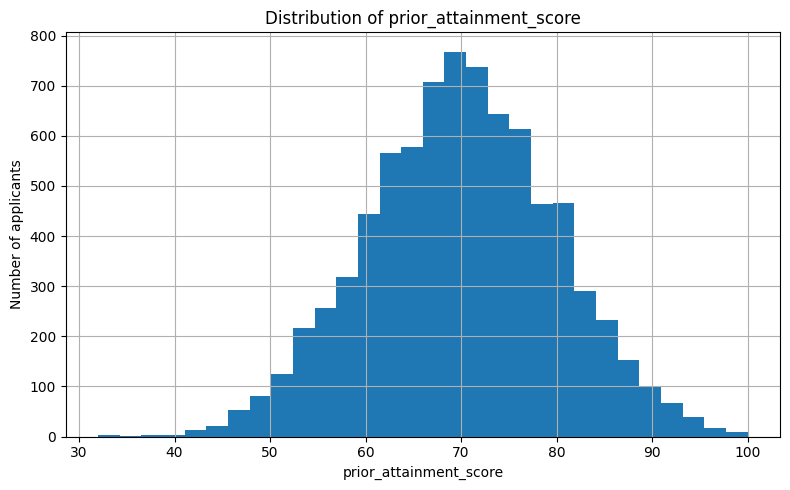

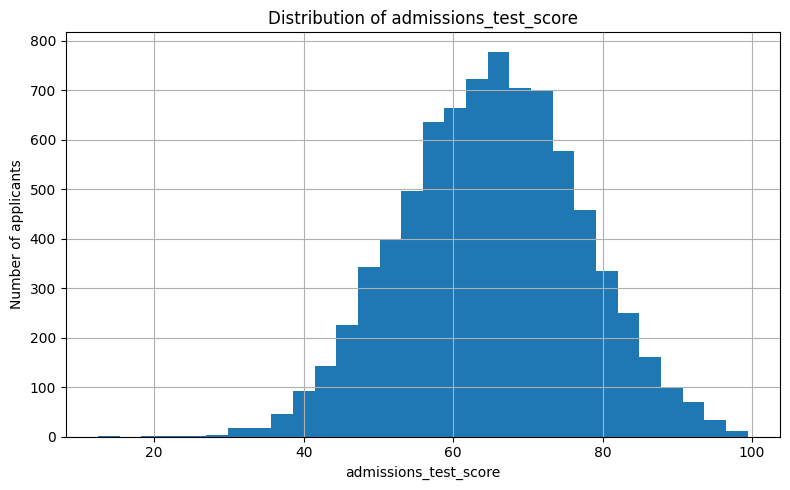

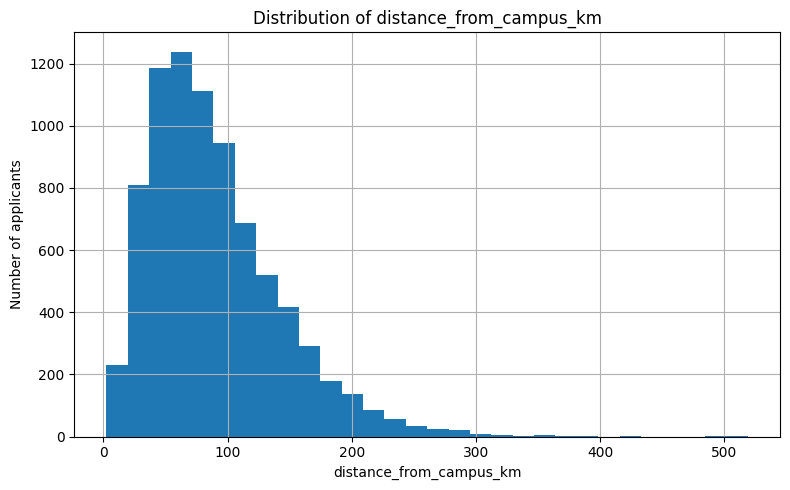

In [27]:

# Plot a histogram for each required numerical variable.
for column in [
    "prior_attainment_score",
    "admissions_test_score",
    "distance_from_campus_km"
]:
    plt.figure(figsize=(8, 5))

    data[column].dropna().hist(bins=30)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of applicants")
    plt.tight_layout()
    plt.show()


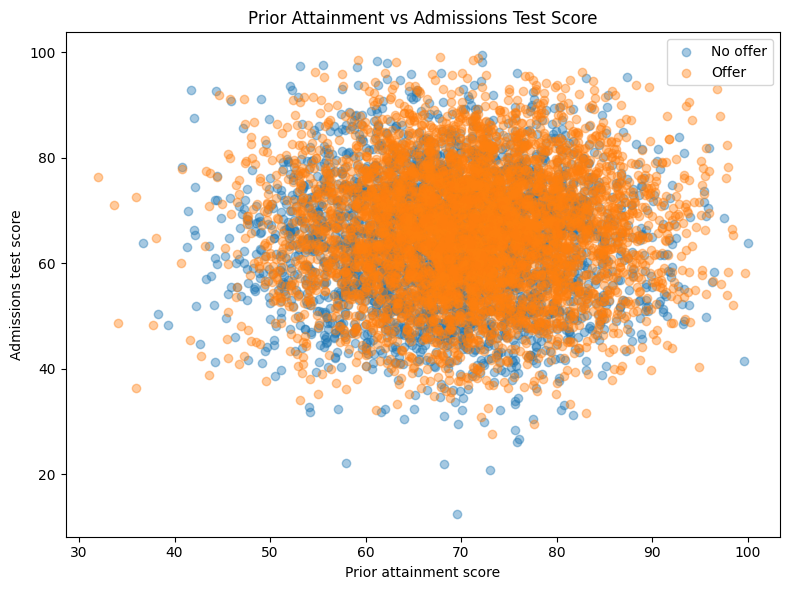

Correlation between academic scores: 0.014


In [28]:

# Compare prior attainment and admissions test scores.
plt.figure(figsize=(8, 6))

for outcome, label in [
    (0, "No offer"),
    (1, "Offer")
]:
    subset = data[
        data["admission_outcome"] == outcome
    ]

    plt.scatter(
        subset["prior_attainment_score"],
        subset["admissions_test_score"],
        alpha=0.4,
        label=label
    )

plt.title(
    "Prior Attainment vs Admissions Test Score"
)
plt.xlabel("Prior attainment score")
plt.ylabel("Admissions test score")
plt.legend()
plt.tight_layout()
plt.show()

# Calculate the correlation between the two scores.
correlation = data[
    [
        "prior_attainment_score",
        "admissions_test_score"
    ]
].corr().iloc[0, 1]

print(
    "Correlation between academic scores:",
    round(correlation, 3)
)


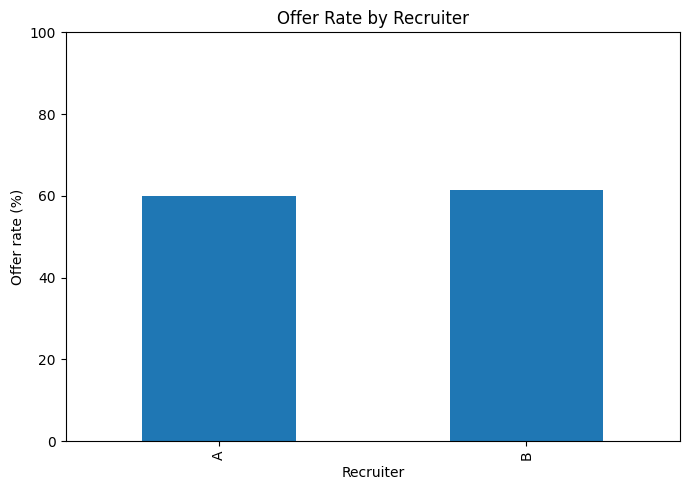

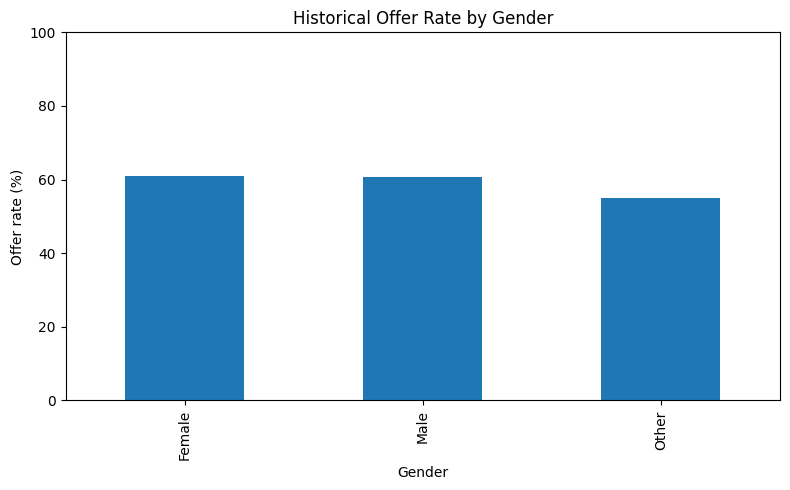

In [29]:

# Historical offer rate by recruitment partner.
recruiter_offer_rates["offer_rate"].plot(
    kind="bar",
    figsize=(7, 5),
    ylim=(0, 100)
)

plt.title("Offer Rate by Recruiter")
plt.xlabel("Recruiter")
plt.ylabel("Offer rate (%)")
plt.tight_layout()
plt.show()

# Historical offer rate by gender.
gender_offer_rates["offer_rate"].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 100)
)

plt.title("Historical Offer Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Offer rate (%)")
plt.tight_layout()
plt.show()


In [30]:

# Predict the historical admission outcome.
target = "admission_outcome"

# Exclude the identifier, target and sensitive attributes
# from the baseline model's predictors.
excluded_columns = [
    "student_id",
    "admission_outcome",
    "gender",
    "ethnicity",
    "disability_status",
    "first_generation_student"
]

feature_columns = [
    column for column in data.columns
    if column not in excluded_columns
]

X = data[feature_columns].copy()
y = data[target].copy()

print("Predictor columns:")
print(feature_columns)

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget class distribution:")
display(y.value_counts().to_frame("count"))


Predictor columns:
['prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'school_type', 'intended_subject_area', 'distance_from_campus_km', 'recruiter_source']

Feature dataset shape: (8000, 7)
Target dataset shape: (8000,)

Target class distribution:


,count
admission_outcome,
1,4850
0,3150


In [31]:

# Separate the dataset into training and test subsets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training offer rate:",
    round(y_train.mean() * 100, 2),
    "%"
)

print(
    "Testing offer rate:",
    round(y_test.mean() * 100, 2),
    "%"
)


Training records: 6400
Testing records: 1600
Training offer rate: 60.62 %
Testing offer rate: 60.62 %


In [32]:

# Identify numeric and categorical predictors.
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Replace missing numerical values with training-set medians.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Replace missing categories with the most frequent category.
# Encode categorical variables numerically.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate transformations to each feature type.
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")


Numeric features: ['prior_attainment_score', 'admissions_test_score', 'personal_statement_score', 'distance_from_campus_km']
Categorical features: ['school_type', 'intended_subject_area', 'recruiter_source']
Preprocessing pipeline created.


In [33]:

# Model 1: Logistic Regression.
# Model 2: Random Forest.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

fitted_models = {}
probabilities = {}
results = []

# Train and evaluate each model using the same held-out test set.
for model_name, estimator in models.items():

    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    model_pipeline.fit(X_train, y_train)

    predictions = model_pipeline.predict(X_test)

    predicted_probabilities = (
        model_pipeline.predict_proba(X_test)[:, 1]
    )

    fitted_models[model_name] = model_pipeline
    probabilities[model_name] = predicted_probabilities

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, predicted_probabilities
        ),
        "Log Loss": log_loss(
            y_test,
            predicted_probabilities,
            labels=[0, 1]
        )
    })

print("Both models have been trained and evaluated.")


Both models have been trained and evaluated.


In [34]:

# Create a comparison table of both models.
results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
Model,,,,,,
Logistic Regression,0.5569,0.6548,0.5691,0.6089,0.5717,0.6840
Random Forest,0.5656,0.6263,0.7031,0.6625,0.5504,0.6794



Logistic Regression
              precision    recall  f1-score   support

           0       0.45      0.54      0.49       630
           1       0.65      0.57      0.61       970

    accuracy                           0.56      1600
   macro avg       0.55      0.55      0.55      1600
weighted avg       0.57      0.56      0.56      1600



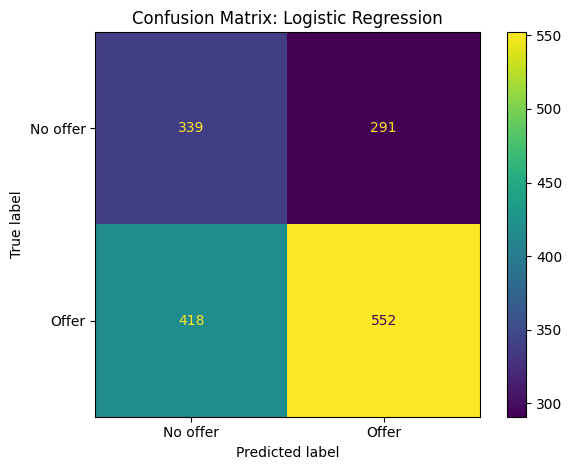


Random Forest
              precision    recall  f1-score   support

           0       0.44      0.35      0.39       630
           1       0.63      0.70      0.66       970

    accuracy                           0.57      1600
   macro avg       0.53      0.53      0.53      1600
weighted avg       0.55      0.57      0.56      1600



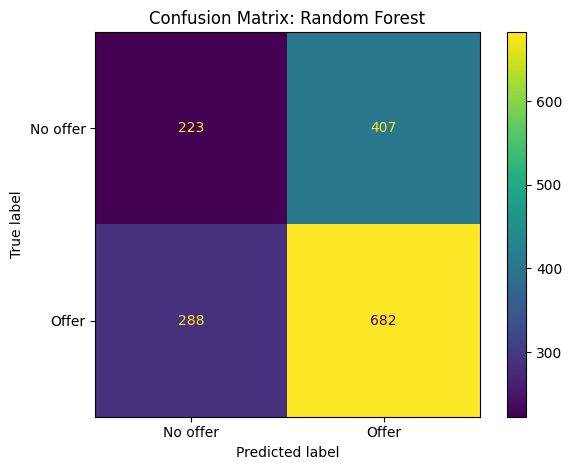

In [35]:

for model_name, model_pipeline in fitted_models.items():

    predictions = model_pipeline.predict(X_test)

    print(f"\n{model_name}")
    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No offer", "Offer"]
    )

    display_matrix.plot(values_format="d")

    plt.title(f"Confusion Matrix: {model_name}")
    plt.tight_layout()
    plt.show()


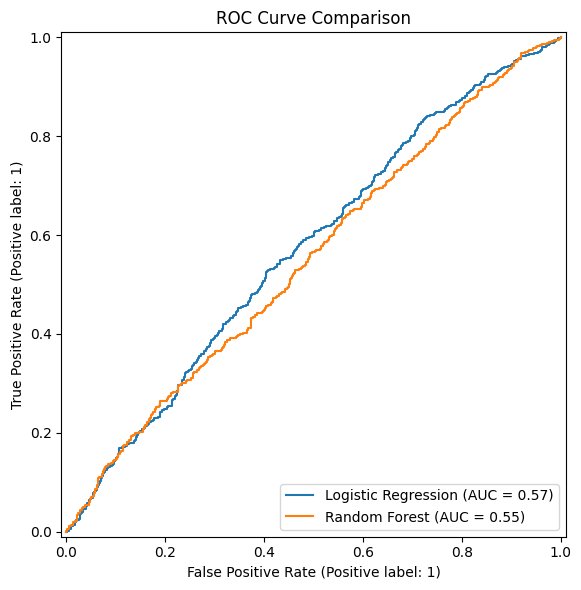

In [36]:

plt.figure(figsize=(8, 6))
ax = plt.gca()

for model_name, model_pipeline in fitted_models.items():
    RocCurveDisplay.from_estimator(
        model_pipeline,
        X_test,
        y_test,
        ax=ax,
        name=model_name
    )

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()


In [37]:

# Use protected characteristics for auditing only,
# not as predictors in the baseline models.
audit_test = data.loc[
    X_test.index,
    [
        "gender",
        "ethnicity",
        "disability_status",
        "recruiter_source"
    ]
].copy()

audit_test["actual_offer"] = y_test

# Add predicted outcomes from both trained models.
for model_name, model_pipeline in fitted_models.items():
    audit_test[f"{model_name}_prediction"] = (
        model_pipeline.predict(X_test)
    )

# Compare actual and predicted offer rates across groups.
for group_column in [
    "gender",
    "ethnicity",
    "disability_status",
    "recruiter_source"
]:
    print(f"\nFairness audit: {group_column}")

    prediction_columns = [
        f"{name}_prediction"
        for name in fitted_models
    ]

    group_summary = audit_test.groupby(
        group_column,
        dropna=False
    )[["actual_offer"] + prediction_columns].agg(
        ["count", "mean"]
    )

    display(group_summary.round(3))



Fairness audit: gender


actual_offer        Logistic Regression_prediction         \
              count   mean                          count   mean   
gender                                                             
Female          812  0.602                            812  0.507   
Male            757  0.613                            757  0.552   
Other            31  0.548                             31  0.419   

       Random Forest_prediction         
                          count   mean  
gender                                  
Female                      812  0.677  
Male                        757  0.690  
Other                        31  0.548


Fairness audit: ethnicity


actual_offer        Logistic Regression_prediction         \
                 count   mean                          count   mean   
ethnicity                                                             
Asian              299  0.619                            299  0.525   
Black              305  0.643                            305  0.525   
Mixed              326  0.598                            326  0.540   
Other              340  0.588                            340  0.506   
White              330  0.588                            330  0.539   

          Random Forest_prediction         
                             count   mean  
ethnicity                                  
Asian                          299  0.729  
Black                          305  0.603  
Mixed                          326  0.721  
Other                          340  0.665  
White                          330  0.685


Fairness audit: disability_status


actual_offer        Logistic Regression_prediction         \
                         count   mean                          count   mean   
disability_status                                                             
Learning                   150  0.627                            150  0.540   
Mental                      99  0.667                             99  0.525   
Physical                    99  0.556                             99  0.556   
NaN                       1252  0.603                           1252  0.523   

                  Random Forest_prediction         
                                     count   mean  
disability_status                                  
Learning                               150  0.633  
Mental                                  99  0.768  
Physical                                99  0.667  
NaN                                   1252  0.681


Fairness audit: recruiter_source


actual_offer        Logistic Regression_prediction         \
                        count   mean                          count   mean   
recruiter_source                                                             
A                         773  0.587                            773  0.502   
B                         827  0.624                            827  0.550   

                 Random Forest_prediction         
                                    count   mean  
recruiter_source                                  
A                                     773  0.673  
B                                     827  0.688

In [38]:

# Select the model with the highest F1 score for initial comparison.
provisional_best = results_df["F1 Score"].idxmax()

print("Provisional model:", provisional_best)

print("\nSelected model's performance:")
display(results_df.loc[[provisional_best]].round(4))

print(
    "\nThis is a provisional statistical comparison, not approval "
    "for operational use. Review recall, precision, fairness, "
    "explainability and the consequences of errors before deciding."
)


Provisional model: Random Forest

Selected model's performance:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss
Model,,,,,,
Random Forest,0.5656,0.6263,0.7031,0.6625,0.5504,0.6794



This is a provisional statistical comparison, not approval for operational use. Review recall, precision, fairness, explainability and the consequences of errors before deciding.


In [39]:

# Record software versions to support reproducibility.
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nFinal cleaned dataset shape:", data.shape)
print("Number of predictors:", len(feature_columns))
print("Training set size:", len(X_train))
print("Test set size:", len(X_test))

print("\nFinal target distribution:")
display(
    data["admission_outcome"]
    .value_counts()
    .rename("count")
    .to_frame()
)

print("\nNotebook analysis completed.")


Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

Final cleaned dataset shape: (8000, 13)
Number of predictors: 7
Training set size: 6400
Test set size: 1600

Final target distribution:


,count
admission_outcome,
1,4850
0,3150



Notebook analysis completed.



## Limitations, Governance and Maintenance

1. **Target validity:** The target variable represents historical offer decisions, not subsequent academic success or graduation. Therefore, model predictions cannot establish which applicants are most likely to succeed academically.

2. **Data quality:** Missing values, inconsistent categories, duplicate identifiers and invalid score ranges must be investigated and documented. Unverified values should not be silently corrected.

3. **Fairness:** Excluding protected characteristics from predictors does not eliminate indirect discrimination. School type, distance from campus and subject area may act as proxies.

4. **Model evaluation:** Accuracy should not be used alone. Precision, recall, F1 score, ROC-AUC, log loss and confusion matrices provide complementary evidence.

5. **Human oversight:** The model should support admissions officers rather than automatically accept or reject applicants. Staff must retain responsibility for final decisions.

6. **Transparency:** Document the variables used, model limitations, training data, validation results and reasons for recommendations.

7. **Data protection:** Apply appropriate access controls, data minimisation, retention policies and institutional governance requirements.

8. **Code maintenance:** Use Git for version control, comments for maintainability, documented dependencies and repeatable validation tests.

9. **Ongoing monitoring:** Reassess model performance and group-level outcomes on later applicant cohorts before considering any continued use.

10. **Recommendation:** Consider only a controlled decision-support pilot after data validation, fairness assessment, governance approval and human-oversight arrangements are established.
